In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/credit_card_default.csv')

print('Размер датасета:', df.shape)
display(df.head())

Размер датасета: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
df.info()
print('\n')
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


Пропущенных значений нет, дубликаты строк отсутствуют. Средние значения BILL_AMT заметно превышают медианы, у нас - правосторонняя ассиметрия и наличие крупных задолженностей. Возраст клиентов находится в диапазоне 21–79 лет

Проверим дисбаланс классов по дефолту

In [4]:
print(df['default.payment.next.month'].value_counts())
print((df['default.payment.next.month'].value_counts()[1] / df['default.payment.next.month'].count()) * 100)


default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64
22.12


Умеренный дисбаланс

Значения PAY_0 — PAY_6 имеют порядковую структуру(своевременность погашения задложенности)

In [5]:
print(df['MARRIAGE'].value_counts().sort_index())
print('\n')
print(df['EDUCATION'].value_counts().sort_index())

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64


Признак EDUCATION содержат дополнительные неописанные категории(0, 5, 6), а также 0 в признаке MARRIAGE

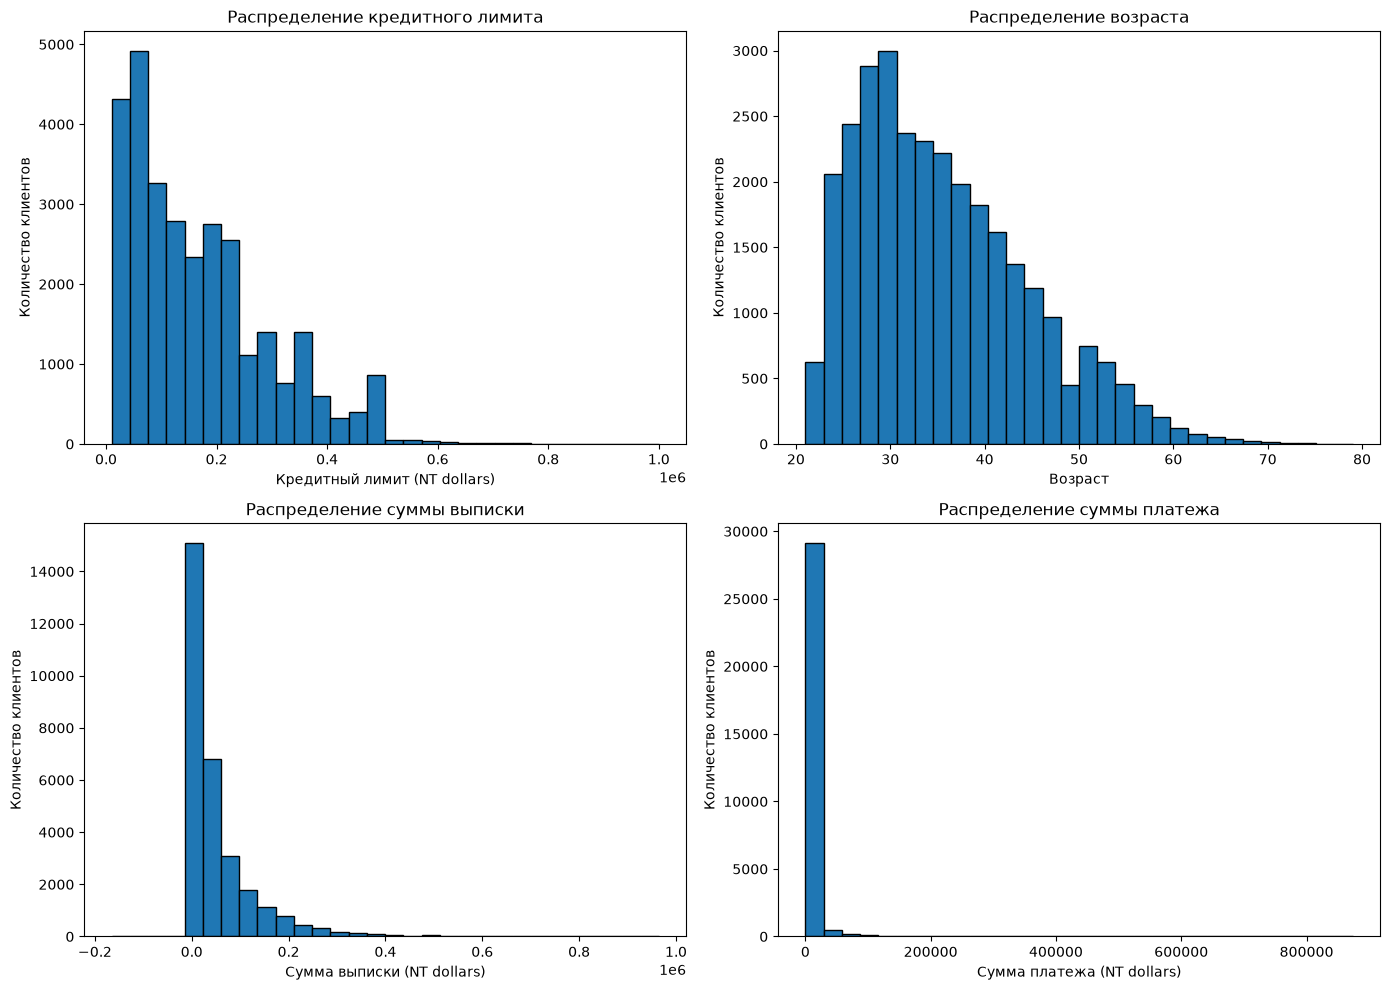

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Кредитный лимит
axes[0, 0].hist(df['LIMIT_BAL'], bins=30, edgecolor='black')
axes[0, 0].set_title('Распределение кредитного лимита')
axes[0, 0].set_xlabel('Кредитный лимит (NT dollars)')
axes[0, 0].set_ylabel('Количество клиентов')

# Возраст
axes[0, 1].hist(df['AGE'], bins=30, edgecolor='black')
axes[0, 1].set_title('Распределение возраста')
axes[0, 1].set_xlabel('Возраст')
axes[0, 1].set_ylabel('Количество клиентов')

# Сумма выписки за сентябрь
axes[1, 0].hist(df['BILL_AMT1'], bins=30, edgecolor='black')
axes[1, 0].set_title('Распределение суммы выписки')
axes[1, 0].set_xlabel('Сумма выписки (NT dollars)')
axes[1, 0].set_ylabel('Количество клиентов')

# Сумма предыдущего платежа за сентябрь
axes[1, 1].hist(df['PAY_AMT1'], bins=30, edgecolor='black')
axes[1, 1].set_title('Распределение суммы платежа')
axes[1, 1].set_xlabel('Сумма платежа (NT dollars)')
axes[1, 1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.show()

Видим правостороннюю асимметрию LIMIT_BAL. Основная масса клиентов сосредоточена в диапазоне относительно небольших кредитных лимитов. Основной массе клиентов примерно 25-45 лет. По BILL_AMT1 также очень сильная правосторонняя асимметрия. Большинство платежей относительно небольшие, однако присутствуют отдельные очень крупные платежи. Значения PAY_AMT1 почти все расположены внутри нуля с очень длинным правым хвостом

Распределения финансовых признаков существенно отличаются от нормального распределения и датасет имеет особенности кодирования признаков, но, в остальном, не имеет очевидных проблем

In [9]:
from pd_model.features import create_features

df = create_features(df)
print(df.shape)

(30000, 32)


In [14]:
from pd_model.validation import validate_data
from pd_model.features import create_features

df = validate_data(df)
df = create_features(df)